In [1]:
# 边缘检测->获取轮廓->变换

import numpy as np
import matplotlib.pyplot as plt
import argparse
import cv2


def resize(image, width=None, height=None, inter=cv2.INTER_AREA):
    dim = None
    (h, w) = image.shape[:2] #返回值(height, width, channels)
    if width is None and height is None:
        return image
    if width is None:
        r = height / float(h)
        dim = (int(w * r), height)
    else:
        r = width / float(w)
        dim = (width, int(h * r))
    resized = cv2.resize(image, dim, interpolation = inter)
    return resized

def four_point_transform(image, pts):
	# 获取输入坐标点
	rect = order_points(pts)
	(tl, tr, br, bl) = rect

	# 计算输入的w和h值
	widthA = np.sqrt(((br[0] - bl[0]) ** 2) + ((br[1] - bl[1]) ** 2))
	widthB = np.sqrt(((tr[0] - tl[0]) ** 2) + ((tr[1] - tl[1]) ** 2))
	maxWidth = max(int(widthA), int(widthB))

	heightA = np.sqrt(((tr[0] - br[0]) ** 2) + ((tr[1] - br[1]) ** 2))
	heightB = np.sqrt(((tl[0] - bl[0]) ** 2) + ((tl[1] - bl[1]) ** 2))
	maxHeight = max(int(heightA), int(heightB))

	# 变换后对应坐标位置
	dst = np.array([ [0, 0], [maxWidth - 1, 0], [maxWidth - 1, maxHeight - 1], [0, maxHeight - 1]], dtype = "float32")

	# 计算变换矩阵
	M = cv2.getPerspectiveTransform(rect, dst)
	warped = cv2.warpPerspective(image, M, (maxWidth, maxHeight))

	# 返回变换后结果
	return warped

def order_points(pts):
	# 一共4个坐标点
	rect = np.zeros((4, 2), dtype = "float32")

	# 按顺序找到对应坐标0123分别是 左上，右上，右下，左下
	# 计算左上，右下
	s = pts.sum(axis = 1)
	rect[0] = pts[np.argmin(s)]
	rect[2] = pts[np.argmax(s)]

	# 计算右上和左下
	diff = np.diff(pts, axis = 1)
	rect[1] = pts[np.argmin(diff)]
	rect[3] = pts[np.argmax(diff)]

	return rect

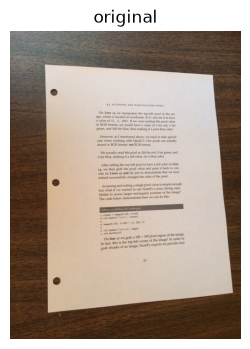

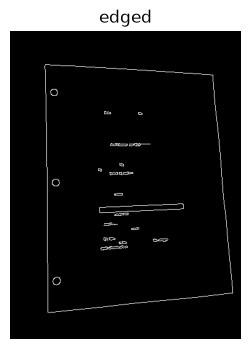

In [2]:

image = cv2.imread("page.jpg")


plt.figure(figsize=(3,4))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)) # 加上BGR转RGB，否则plt显示颜色不对
plt.title("original")
plt.axis('off')
plt.show()

# 用于图像的缩放或尺寸归一化
ratio = image.shape[0] / 500.0  #image.shape[0]获取图的高度，选用500是个经验值
orig = image.copy()  #若是在透视变换那边取缩放后的图片，会导致输出的结果为一张黑色的图片
# new_width = int(orig.shape[1] / ratio)

# 将图像高度调整为500像素
image = resize(orig, height = 500)  #定义的resize函数会自动保持宽高比
 
# 预处理
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

gray = cv2.GaussianBlur(gray, (3,3), 0)
# 边缘检测
edged = cv2.Canny(gray, 70, 255)

plt.figure(figsize=(3,4))
plt.imshow(edged, cmap='gray')
plt.title("edged")
plt.axis('off')
plt.show()



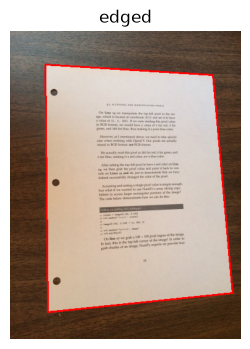

In [3]:
# 二值化处理
_, thresh = cv2.threshold(edged, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

# 轮廓检测
cnts = cv2.findContours(thresh.copy(), cv2.RETR_LIST, cv2.CHAIN_APPROX_SIMPLE)[0]  #返回两个值 (contours轮廓, hierarchy（层级信息))

#排序，因为有可能一张图片上面会有几张小票
cnts = sorted(cnts, key=cv2.contourArea, reverse=True)[:5]

screenCnt = None 
# 遍历轮廓
for c in cnts:
    #计算轮廓的周长
    peri = cv2.arcLength(c, True) 
    # 计算轮廓近似
    # c表示输入的点集
    # epsilon表示从原始轮廓到近似轮廓的最大距离，它是一个准确度参数
    # True表示封闭的
    approx = cv2.approxPolyDP(c, 0.02 * peri, True)
    # 4个点的时候读进来
    if len(approx) == 4:
        screenCnt = approx
        break

# 防止上面没有执行，screenCnt是None引发报错
if screenCnt is None: 
    print("未检测到文档边缘")
else:
    cv2.drawContours(image, [screenCnt ], -1, (0,0,255), 2)
    
plt.figure(figsize=(3,4))
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("edged")
plt.axis('off')
plt.show()

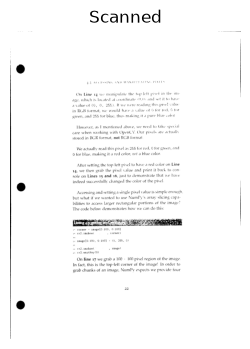

In [4]:
# 透视转换
warped = four_point_transform(orig, screenCnt.reshape(4, 2) * ratio)

# 二值处理
warped = cv2.cvtColor(warped, cv2.COLOR_BGR2GRAY)
ref = cv2.threshold(warped, 100, 255, cv2.THRESH_BINARY)[1]
cv2.imwrite('scan.jpg', ref)

# 展示结果
# cv2.imshow("Scanned", resize(ref, height = 650))

plt.figure(figsize=(3,4))
plt.imshow(ref, cmap='gray')
plt.title("Scanned")
plt.axis('off')
plt.show()


13 VOU ESAENG UNG SEAYNTE PD Vet ye eas

On Line fg we manipulate tine top deft paseb a tiie a
dee whichis docated at Coordinate (00) and set it te hase
wvoalue ot 69, 8, 255: Ttawe were reading this pres ALTE
In RGB tormat, we would have a value of for red. % sor

green, and 255 tor blue, thus making ita pure blac obo

Tlowever, as | mentioned above, we need to take spectra:
care when working with Open€ Vo Qur preety are as tualis
stored in BGR tormat, not RGB format

We actually read this pixelas 255 for red, © for green, and
O tor blue, making ita red color, vel a blue color

After setting the top lett pixel to have a red color on Line
1p. we then grab the pixel value and print it back to con
sole on Lines 15 and 16, just to demonstrate that we bave
indeed successtully Changed the color of the pixel

Accessing and setting a single pred value is simple enough
but what if we wanted to use Numl’ys array sheng, capa:

bilities to access larger rectangular portions of the image?

The cod

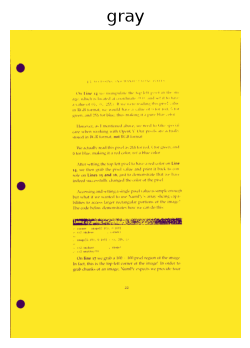

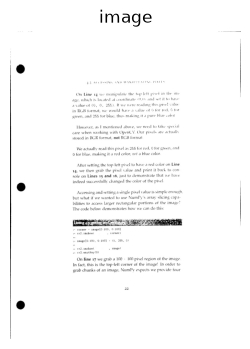

In [5]:
from PIL import Image
import pytesseract
import cv2
import os
import matplotlib.pyplot as plt

# 关键修复：告诉 pytesseract 引擎装在哪（Jupyter 内核继承不到新装的 PATH）
pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"

preprocess = 'blur' #thresh

image = cv2.imread('scan.jpg')
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

if preprocess == "thresh":
    gray = cv2.threshold(gray, 0, 255,cv2.THRESH_BINARY | cv2.THRESH_OTSU)[1]

if preprocess == "blur":
    gray = cv2.medianBlur(gray, 3)
    
filename = "{}.png".format(os.getpid())
cv2.imwrite(filename, gray)
    
text = pytesseract.image_to_string(Image.open(filename))
print(text)
os.remove(filename)

# cv2.imshow("Image", image)  # Jupyter 里会卡住，改用下面的 matplotlib 展示
# cv2.imshow("Output", gray)
# cv2.waitKey(0)                                   

plt.figure(figsize=(3,4))
plt.imshow(gray)
plt.title("gray")
plt.axis('off')
plt.show()

plt.figure(figsize=(3,4))
plt.imshow(image)
plt.title("image")
plt.axis('off')
plt.show()